### Chamando bibliotecas

In [ ]:
#Manipulação dos dados
from joblib import load, dump
import pandas as pd

#Geração de gráficos
import matplotlib.pyplot as plt
import seaborn as sns

#Operações
import numpy as np


In [36]:
#Importando tabela inicial
df = pd.read_csv("../tabelas/tabela_inicial.csv")
df

,grupo,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,n_OXA51,n_ADC,n_tetX,MIC_imipenem,n_carbapenemases
0,Sepse,2,1,2,1,3,1,1,0,1,0,1,0,0,0,1,1,0,64.00,3
1,Ambiental,0,0,0,0,2,0,1,0,0,0,0,0,0,1,1,1,0,0.50,0
2,Sepse,1,0,2,1,3,2,2,1,1,1,2,1,0,0,1,1,0,8.00,1
3,Sepse,2,1,2,2,3,1,2,1,1,1,1,1,0,0,1,1,0,64.00,3
4,Ambiental,1,0,0,0,1,0,0,0,0,0,0,0,2,1,1,1,0,0.50,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1095,Ambiental,1,0,0,0,2,0,0,0,0,0,0,0,2,0,1,1,0,1.00,1
1096,Sepse,0,0,0,1,2,2,1,1,1,1,2,1,0,0,1,1,0,2.00,0
1097,Ambiental,0,0,0,1,0,1,0,0,0,0,0,0,2,0,1,1,0,0.25,0
1098,Ambiental,0,0,0,1,2,0,0,1,0,0,0,0,2,1,1,1,0,0.25,0


### Retirando features constantes

In [37]:
#Identificando colunas constantes
colunas = df.columns
for coluna in colunas:
    print(df[coluna].value_counts())

grupo
Sepse        561
Ambiental    539
Name: count, dtype: int64
n_OXA
0    429
1    364
2    307
Name: count, dtype: int64
n_MBL
0    584
1    516
Name: count, dtype: int64
n_ISAba1
0    400
1    354
2    346
Name: count, dtype: int64
n_ESBL
0    381
2    375
1    344
Name: count, dtype: int64
n_aminoglicosideos
3    293
0    284
2    273
1    250
Name: count, dtype: int64
n_sulfa_trimetoprim
2    378
0    373
1    349
Name: count, dtype: int64
n_quinolonas
2    379
0    370
1    351
Name: count, dtype: int64
n_tetraciclina
0    560
1    540
Name: count, dtype: int64
n_efluxo_adeS
0    569
1    531
Name: count, dtype: int64
n_polimixinas
0    558
1    542
Name: count, dtype: int64
n_virulencia_clinica
0    585
1    270
2    245
Name: count, dtype: int64
n_ilha_AbaR
0    628
1    472
Name: count, dtype: int64
n_resistencia_metais
0    586
1    274
2    240
Name: count, dtype: int64
n_degradacao_aromaticos
0    611
1    489
Name: count, dtype: int64
n_OXA51
1    1100
Name: count, dtype

In [38]:
#Retirando colunas constantes
df = df.drop(columns=["n_OXA51","n_ADC","n_tetX"])
df

,grupo,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,n_carbapenemases
0,Sepse,2,1,2,1,3,1,1,0,1,0,1,0,0,0,64.00,3
1,Ambiental,0,0,0,0,2,0,1,0,0,0,0,0,0,1,0.50,0
2,Sepse,1,0,2,1,3,2,2,1,1,1,2,1,0,0,8.00,1
3,Sepse,2,1,2,2,3,1,2,1,1,1,1,1,0,0,64.00,3
4,Ambiental,1,0,0,0,1,0,0,0,0,0,0,0,2,1,0.50,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1095,Ambiental,1,0,0,0,2,0,0,0,0,0,0,0,2,0,1.00,1
1096,Sepse,0,0,0,1,2,2,1,1,1,1,2,1,0,0,2.00,0
1097,Ambiental,0,0,0,1,0,1,0,0,0,0,0,0,2,0,0.25,0
1098,Ambiental,0,0,0,1,2,0,0,1,0,0,0,0,2,1,0.25,0


Duplicatas

In [39]:
#Verificando colunas duplicadas
df.duplicated().sum()

np.int64(100)

In [40]:
#Retirando linhas duplicadas
df = df.drop_duplicates()
df

,grupo,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,n_carbapenemases
0,Sepse,2,1,2,1,3,1,1,0,1,0,1,0,0,0,64.00,3
1,Ambiental,0,0,0,0,2,0,1,0,0,0,0,0,0,1,0.50,0
2,Sepse,1,0,2,1,3,2,2,1,1,1,2,1,0,0,8.00,1
3,Sepse,2,1,2,2,3,1,2,1,1,1,1,1,0,0,64.00,3
4,Ambiental,1,0,0,0,1,0,0,0,0,0,0,0,2,1,0.50,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1095,Ambiental,1,0,0,0,2,0,0,0,0,0,0,0,2,0,1.00,1
1096,Sepse,0,0,0,1,2,2,1,1,1,1,2,1,0,0,2.00,0
1097,Ambiental,0,0,0,1,0,1,0,0,0,0,0,0,2,0,0.25,0
1098,Ambiental,0,0,0,1,2,0,0,1,0,0,0,0,2,1,0.25,0


### Distribução da coluna MIC_imipenem

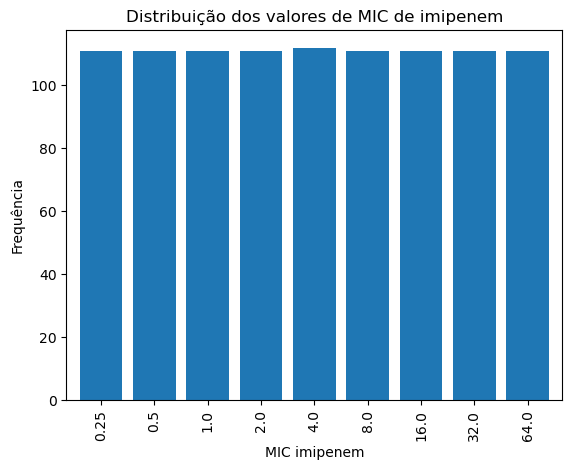

In [41]:
df["MIC_imipenem"].value_counts().sort_index().plot(
    kind="bar",
    width=0.8
)

plt.xlabel("MIC imipenem")
plt.ylabel("Frequência")
plt.title("Distribuição dos valores de MIC de imipenem")
plt.show()

### Avaliando correlação

In [42]:
#Gerando imagem de correlação
img_corr = df.select_dtypes(include='number').corr()
img_corr.style.background_gradient(cmap='coolwarm')

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,n_carbapenemases
n_OXA,1.000000,0.452026,0.490232,0.164726,0.195038,0.218248,0.228976,0.252882,0.502011,0.253365,0.233693,0.237877,-0.285945,-0.231534,0.692222,0.919368
n_MBL,0.452026,1.000000,0.500044,0.294560,0.307392,0.340385,0.337074,0.375565,0.507251,0.391829,0.352823,0.397782,-0.400871,-0.386386,0.601648,0.766492
n_ISAba1,0.490232,0.500044,1.000000,0.216491,0.256841,0.276284,0.267710,0.311773,0.559656,0.316860,0.291335,0.307614,-0.331817,-0.282401,0.566239,0.573506
n_ESBL,0.164726,0.294560,0.216491,1.000000,0.558509,0.608099,0.626151,0.722498,0.323200,0.712769,0.509348,0.550819,-0.564660,-0.583402,0.237440,0.248514
n_aminoglicosideos,0.195038,0.307392,0.256841,0.558509,1.000000,0.566696,0.565493,0.672001,0.339671,0.687706,0.482020,0.529047,-0.531369,-0.566932,0.274048,0.275998
n_sulfa_trimetoprim,0.218248,0.340385,0.276284,0.608099,0.566696,1.000000,0.613313,0.719645,0.373476,0.734088,0.530418,0.585778,-0.571260,-0.586284,0.264347,0.307260
n_quinolonas,0.228976,0.337074,0.267710,0.626151,0.565493,0.613313,1.000000,0.726267,0.372581,0.723747,0.516309,0.558242,-0.565192,-0.582927,0.285578,0.313524
n_tetraciclina,0.252882,0.375565,0.311773,0.722498,0.672001,0.719645,0.726267,1.000000,0.419659,0.831953,0.638599,0.665742,-0.675266,-0.698775,0.342569,0.347713
n_efluxo_adeS,0.502011,0.507251,0.559656,0.323200,0.339671,0.373476,0.372581,0.419659,1.000000,0.431764,0.386913,0.425875,-0.402358,-0.410375,0.528294,0.585166
n_polimixinas,0.253365,0.391829,0.316860,0.712769,0.687706,0.734088,0.723747,0.831953,0.431764,1.000000,0.637628,0.682408,-0.693463,-0.702300,0.328891,0.355233


In [43]:
#Mostrando alta correlação (80%)
limite = 0.80
img_corr[img_corr > limite].style.background_gradient(cmap='coolwarm')

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,n_carbapenemases
n_OXA,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.919368
n_MBL,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_ISAba1,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_ESBL,nan,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_aminoglicosideos,nan,nan,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_sulfa_trimetoprim,nan,nan,nan,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_quinolonas,nan,nan,nan,nan,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_tetraciclina,nan,nan,nan,nan,nan,nan,nan,1.000000,nan,0.831953,nan,nan,nan,nan,nan,nan
n_efluxo_adeS,nan,nan,nan,nan,nan,nan,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan
n_polimixinas,nan,nan,nan,nan,nan,nan,nan,0.831953,nan,1.000000,nan,nan,nan,nan,nan,nan


In [44]:
#Mostrando alta correlação (85%)
limite = 0.85
img_corr[img_corr > limite].style.background_gradient(cmap='coolwarm')

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,n_carbapenemases
n_OXA,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.919368
n_MBL,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_ISAba1,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_ESBL,nan,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_aminoglicosideos,nan,nan,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_sulfa_trimetoprim,nan,nan,nan,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_quinolonas,nan,nan,nan,nan,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_tetraciclina,nan,nan,nan,nan,nan,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan,nan
n_efluxo_adeS,nan,nan,nan,nan,nan,nan,nan,nan,1.000000,nan,nan,nan,nan,nan,nan,nan
n_polimixinas,nan,nan,nan,nan,nan,nan,nan,nan,nan,1.000000,nan,nan,nan,nan,nan,nan


In [45]:
#Verificando alta correlação negativa 
img_corr[img_corr < -limite].style.background_gradient(cmap='coolwarm')

/home/isabel.ribeiro/.conda/envs/projeto_ml/lib/python3.11/site-packages/pandas/io/formats/style.py:3807: RuntimeWarning: All-NaN slice encountered
  smin = np.nanmin(gmap) if vmin is None else vmin
/home/isabel.ribeiro/.conda/envs/projeto_ml/lib/python3.11/site-packages/pandas/io/formats/style.py:3808: RuntimeWarning: All-NaN slice encountered
  smax = np.nanmax(gmap) if vmax is None else vmax


,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,n_carbapenemases
n_OXA,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_MBL,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_ISAba1,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_ESBL,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_aminoglicosideos,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_sulfa_trimetoprim,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_quinolonas,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_tetraciclina,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_efluxo_adeS,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
n_polimixinas,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


In [46]:
#Avaliando correlação para cada um dos grupos 
for g in df['grupo'].dropna().unique():
    print(f"Grupo: {g}")

    corr = (
        df[df['grupo'] == g]
        .select_dtypes(include='number')
        .corr()
    )

    display(corr.style.background_gradient(cmap='coolwarm'))

Grupo: Sepse


,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,n_carbapenemases
n_OXA,1.000000,0.338252,0.468478,-0.028649,0.082098,0.044395,0.068077,-0.106985,0.374565,-0.087161,-0.050898,-0.094241,-0.021655,0.072153,0.686273,0.914115
n_MBL,0.338252,1.000000,0.377903,-0.024131,0.042224,-0.013475,0.038637,-0.128329,0.274775,-0.078697,-0.075014,-0.025381,-0.001485,0.054795,0.513833,0.690756
n_ISAba1,0.468478,0.377903,1.000000,-0.015740,0.115418,0.047936,0.071946,-0.033072,0.469612,-0.088502,-0.051787,-0.042471,0.051340,0.045843,0.485647,0.522788
n_ESBL,-0.028649,-0.024131,-0.015740,1.000000,0.203579,0.298306,0.307556,0.415166,-0.017269,0.368436,-0.075074,-0.043203,0.037277,-0.027596,-0.083829,-0.032410
n_aminoglicosideos,0.082098,0.042224,0.115418,0.203579,1.000000,0.249040,0.238515,0.307215,0.094612,0.398516,-0.045174,0.020452,0.070976,-0.050227,0.025081,0.081275
n_sulfa_trimetoprim,0.044395,-0.013475,0.047936,0.298306,0.249040,1.000000,0.320942,0.362326,0.036202,0.399696,-0.052077,0.028113,0.090797,-0.081459,-0.047664,0.028306
n_quinolonas,0.068077,0.038637,0.071946,0.307556,0.238515,0.320942,1.000000,0.387013,0.060585,0.381201,-0.091956,-0.046652,-0.027224,-0.051279,-0.016947,0.068956
n_tetraciclina,-0.106985,-0.128329,-0.033072,0.415166,0.307215,0.362326,0.387013,1.000000,-0.035165,0.434046,-0.052139,-0.054514,0.012692,-0.052079,-0.016248,-0.137496
n_efluxo_adeS,0.374565,0.274775,0.469612,-0.017269,0.094612,0.036202,0.060585,-0.035165,1.000000,-0.073151,-0.050028,-0.016520,0.023802,0.062880,0.377936,0.406195
n_polimixinas,-0.087161,-0.078697,-0.088502,0.368436,0.398516,0.399696,0.381201,0.434046,-0.073151,1.000000,-0.049158,0.002247,0.069815,-0.055843,-0.060873,-0.100880


Grupo: Ambiental


,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,n_carbapenemases
n_OXA,1.000000,0.359488,0.340430,-0.197343,-0.180161,-0.121835,-0.116801,0.013665,0.443170,-0.022437,-0.050397,0.009639,-0.034503,0.105307,0.619681,0.915619
n_MBL,0.359488,1.000000,0.380408,-0.162650,-0.117753,-0.029329,-0.109321,-0.045331,0.396668,-0.045331,-0.055192,0.003603,0.005258,0.058158,0.518196,0.704324
n_ISAba1,0.340430,0.380408,1.000000,-0.182241,-0.146270,-0.071497,-0.131903,-0.058538,0.422249,0.037732,0.039224,0.009639,-0.056410,0.121947,0.524404,0.422875
n_ESBL,-0.197343,-0.162650,-0.182241,1.000000,0.182409,0.153110,0.217269,0.277464,-0.144873,0.277464,-0.042822,0.008190,-0.042347,-0.030702,-0.095302,-0.220203
n_aminoglicosideos,-0.180161,-0.117753,-0.146270,0.182409,1.000000,0.139212,0.143532,0.297899,-0.135705,0.256593,-0.088343,-0.070306,-0.051001,-0.082713,-0.060082,-0.187789
n_sulfa_trimetoprim,-0.121835,-0.029329,-0.071497,0.153110,0.139212,1.000000,0.121031,0.292801,-0.047105,0.323477,0.006132,0.062090,-0.053516,0.032923,-0.065179,-0.105321
n_quinolonas,-0.116801,-0.109321,-0.131903,0.217269,0.143532,0.121031,1.000000,0.292801,-0.082657,0.277464,-0.026504,-0.018760,0.019081,0.032923,-0.026662,-0.135956
n_tetraciclina,0.013665,-0.045331,-0.058538,0.277464,0.297899,0.292801,0.292801,1.000000,-0.087827,0.413341,0.029237,-0.034528,-0.012610,-0.001770,-0.041273,-0.009136
n_efluxo_adeS,0.443170,0.396668,0.422249,-0.144873,-0.135705,-0.047105,-0.082657,-0.087827,1.000000,0.018412,-0.055192,0.003603,0.067148,0.058158,0.488419,0.508038
n_polimixinas,-0.022437,-0.045331,0.037732,0.277464,0.256593,0.323477,0.277464,0.413341,0.018412,1.000000,-0.048782,-0.034528,-0.119410,-0.001770,-0.041085,-0.036599


### Retirando coluna altamente correlacionada

In [ ]:
df = df.drop(columns=["n_carbapenemases"])
df

In [ ]:
#Salvando df pós estruturação
df.to_csv("../tabelas/tabela_estruturada.csv", index= False)